In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

In [33]:
df = pd.read_csv('Crimes_-_2001_to_Present_20261101.csv')
display(df.head())
display(df.describe())
df2 = df.query("Year > 2025")

,ID,Date,Block,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,FBI Code,X Coordinate,Y Coordinate,Year,Latitude,Longitude
0,14368435,10/24/2026 12:00:00 AM,042XX N MARINE DR,CRIMINAL TRESPASS,TO RESIDENCE,RESIDENCE,False,False,1915,19,46.0,26,1170986.0,1928779.0,2026,41.960047,-87.646762
1,14373382,10/24/2026 12:00:00 AM,103XX S VERNON AVE,OTHER OFFENSE,TELEPHONE THREAT,RESIDENCE,False,False,512,5,9.0,08A,1181072.0,1836493.0,2026,41.706580,-87.612529
2,14368301,10/24/2026 12:00:00 AM,085XX S CHAPPEL AVE,ASSAULT,AGGRAVATED - OTHER FIREARM,STREET,False,False,412,4,8.0,04A,1191334.0,1848657.0,2026,41.739717,-87.574557
3,14372254,10/24/2026 12:00:00 AM,0000X N UNKNOWN AVE,CRIMINAL SEXUAL ASSAULT,NON-AGGRAVATED,OTHER (SPECIFY),False,False,6100,61,0.0,02,NaN,NaN,2026,NaN,NaN
4,14368588,10/24/2026 12:00:00 AM,096XX S HOUSTON AVE,CRIMINAL DAMAGE,TO PROPERTY,RESIDENCE - GARAGE,False,False,431,4,10.0,14,1198192.0,1841661.0,2026,41.720351,-87.549665


,ID,Beat,District,Ward,X Coordinate,Y Coordinate,Year,Latitude,Longitude
count,9.517290e+05,951729.000000,951729.000000,951725.000000,9.438430e+05,9.438430e+05,951729.000000,943843.000000,943843.000000
mean,1.362126e+07,1158.118405,11.350725,23.064168,1.165477e+06,1.887359e+06,2024.372249,41.846492,-87.668236
std,7.484415e+05,733.238489,7.326161,13.972820,1.625345e+04,3.150957e+04,1.089697,0.086649,0.059181
min,2.727900e+04,111.000000,1.000000,0.000000,1.091242e+06,1.813897e+06,2023.000000,41.644590,-87.939733
25%,1.329174e+07,532.000000,5.000000,10.000000,1.154163e+06,1.860183e+06,2023.000000,41.771782,-87.709327
50%,1.364367e+07,1033.000000,10.000000,23.000000,1.167350e+06,1.893766e+06,2024.000000,41.864138,-87.660994
75%,1.400378e+07,1732.000000,17.000000,34.000000,1.176796e+06,1.910210e+06,2025.000000,41.909561,-87.626740
max,1.437570e+07,6100.000000,61.000000,50.000000,1.205119e+06,1.951517e+06,2026.000000,42.022559,-87.524529


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 951729 entries, 0 to 951728
Data columns (total 17 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ID                    951729 non-null  int64  
 1   Date                  951729 non-null  str    
 2   Block                 951729 non-null  str    
 3   Primary Type          951729 non-null  str    
 4   Description           951729 non-null  str    
 5   Location Description  946898 non-null  str    
 6   Arrest                951729 non-null  bool   
 7   Domestic              951729 non-null  bool   
 8   Beat                  951729 non-null  int64  
 9   District              951729 non-null  int64  
 10  Ward                  951725 non-null  float64
 11  FBI Code              951729 non-null  str    
 12  X Coordinate          943843 non-null  float64
 13  Y Coordinate          943843 non-null  float64
 14  Year                  951729 non-null  int64  
 15  Latitude   

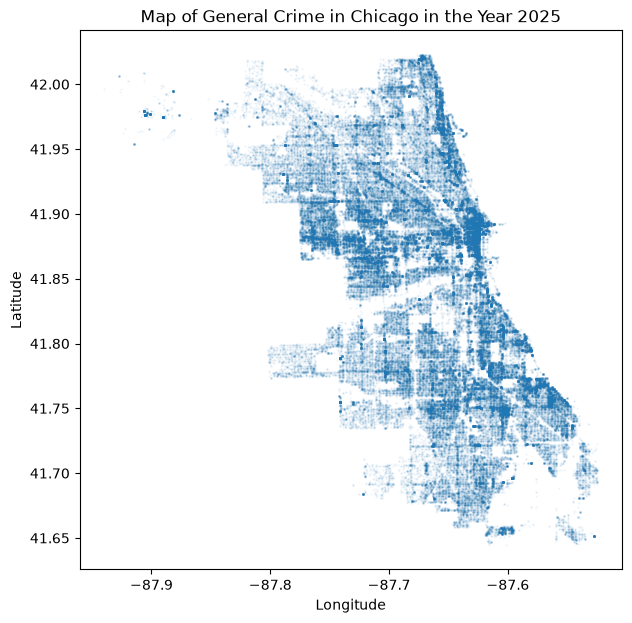

In [ ]:
df2.plot.scatter('Longitude', 'Latitude', s=0.5, alpha=.05, figsize=(7, 7), title = 'Map of General Crime in Chicago in the Year 2025')
plt.savefig('chicagoscatter')
plt.show()

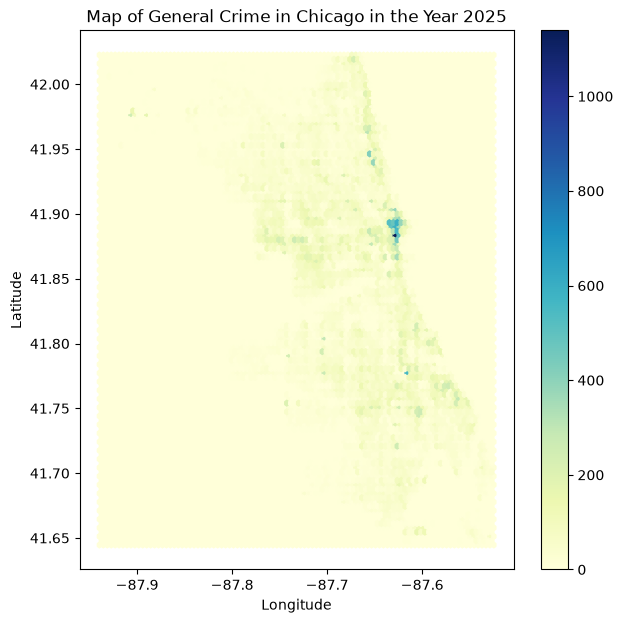

In [8]:
df2.plot.hexbin('Longitude', 'Latitude',  gridsize=100, cmap="YlGnBu", figsize=(7, 7), title = 'Map of General Crime in Chicago in the Year 2025')
plt.savefig('chicagoscatter')
plt.show()

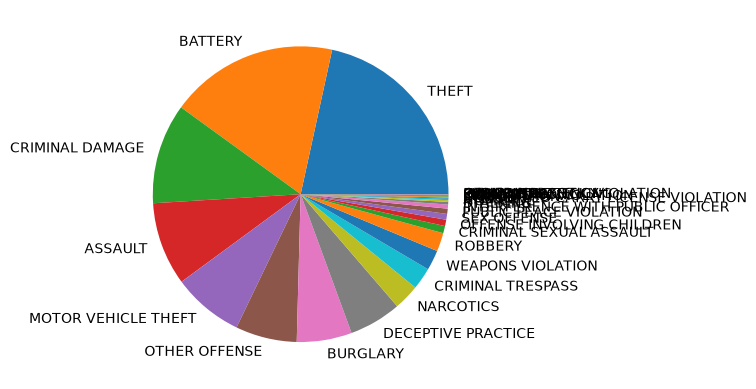

In [8]:
df2['Primary Type'].value_counts().plot.pie()
plt.show()

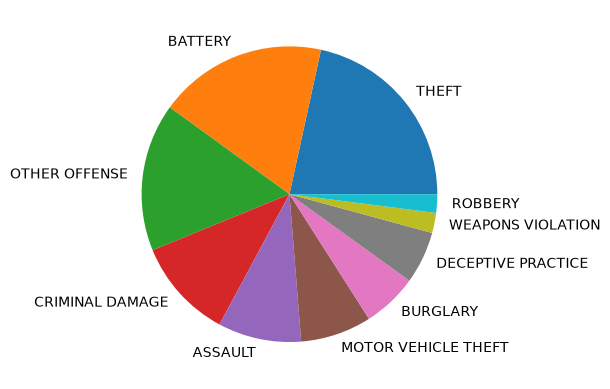

In [12]:
df2['newcol'].value_counts().plot.pie()
plt.show()

In [11]:
df2['newcol'] = df2['newcol'].astype("category")

In [11]:
df2['Primary Type'] = df2['Primary Type'].astype("category")
df2.info()
top_categories = df['Primary Type'].value_counts().nlargest(10).index
print(top_categories)
df2.loc[~df['Primary Type'].isin(top_categories), "newcol"] = "OTHER OFFENSE"
df2.loc[df['Primary Type'].isin(top_categories), "newcol"] = df2['Primary Type']

<class 'pandas.DataFrame'>
RangeIndex: 189983 entries, 0 to 189982
Data columns (total 17 columns):
 #   Column                Non-Null Count   Dtype   
---  ------                --------------   -----   
 0   ID                    189983 non-null  int64   
 1   Date                  189983 non-null  str     
 2   Block                 189983 non-null  str     
 3   Primary Type          189983 non-null  category
 4   Description           189983 non-null  str     
 5   Location Description  189128 non-null  str     
 6   Arrest                189983 non-null  bool    
 7   Domestic              189983 non-null  bool    
 8   Beat                  189983 non-null  int64   
 9   District              189983 non-null  int64   
 10  Ward                  189983 non-null  float64 
 11  FBI Code              189983 non-null  str     
 12  X Coordinate          189595 non-null  float64 
 13  Y Coordinate          189595 non-null  float64 
 14  Year                  189983 non-null  int64   

In [12]:
fig = px.parallel_categories(
    df2,
    dimensions=['Arrest','Primary Type','Domestic'], 
    color=df2['Primary Type'].cat.codes,
    color_continuous_scale=px.colors.qualitative.Set1,
    width=800, height=450,
)
fig.update_traces(line_shape='hspline')
fig.update_layout(coloraxis_showscale=False)
fig.show()
plt.show()

In [13]:
df2['newcol'] = df2['newcol'].astype("category")
fig = px.parallel_categories(
    df2,
    dimensions=['newcol','Arrest'], 
    color=df2['newcol'].cat.codes,
    color_continuous_scale=px.colors.qualitative.Set1,
    width=800, height=450,
)
fig.update_traces(line_shape='hspline')
fig.update_layout(coloraxis_showscale=False)
fig.show()
plt.savefig('alluvial')
plt.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
#run a stacked bar chart for this.
display(df2.head())
#df3 is for the stacked bar chart and contains data 
df3 = df2.pivot_table(index = 'newcol', columns = 'Arrest', values = 'Year', aggfunc = 'count')
df3.head()


,ID,Date,Block,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,FBI Code,X Coordinate,Y Coordinate,Year,Latitude,Longitude,newcol
0,14368435,10/24/2026 12:00:00 AM,042XX N MARINE DR,CRIMINAL TRESPASS,TO RESIDENCE,RESIDENCE,False,False,1915,19,46.0,26,1170986.0,1928779.0,2026,41.960047,-87.646762,OTHER OFFENSE
1,14373382,10/24/2026 12:00:00 AM,103XX S VERNON AVE,OTHER OFFENSE,TELEPHONE THREAT,RESIDENCE,False,False,512,5,9.0,08A,1181072.0,1836493.0,2026,41.706580,-87.612529,OTHER OFFENSE
2,14368301,10/24/2026 12:00:00 AM,085XX S CHAPPEL AVE,ASSAULT,AGGRAVATED - OTHER FIREARM,STREET,False,False,412,4,8.0,04A,1191334.0,1848657.0,2026,41.739717,-87.574557,ASSAULT
3,14372254,10/24/2026 12:00:00 AM,0000X N UNKNOWN AVE,CRIMINAL SEXUAL ASSAULT,NON-AGGRAVATED,OTHER (SPECIFY),False,False,6100,61,0.0,02,NaN,NaN,2026,NaN,NaN,OTHER OFFENSE
4,14368588,10/24/2026 12:00:00 AM,096XX S HOUSTON AVE,CRIMINAL DAMAGE,TO PROPERTY,RESIDENCE - GARAGE,False,False,431,4,10.0,14,1198192.0,1841661.0,2026,41.720351,-87.549665,CRIMINAL DAMAGE


Arrest,False,True
newcol,,
ASSAULT,14963,2342
BATTERY,28299,6710
BURGLARY,11096,340
CRIMINAL DAMAGE,19873,965
DECEPTIVE PRACTICE,10617,249


In [20]:
df2.head()

,ID,Date,Block,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,FBI Code,X Coordinate,Y Coordinate,Year,Latitude,Longitude,newcol
0,14368435,10/24/2026 12:00:00 AM,042XX N MARINE DR,CRIMINAL TRESPASS,TO RESIDENCE,RESIDENCE,False,False,1915,19,46.0,26,1170986.0,1928779.0,2026,41.960047,-87.646762,OTHER OFFENSE
1,14373382,10/24/2026 12:00:00 AM,103XX S VERNON AVE,OTHER OFFENSE,TELEPHONE THREAT,RESIDENCE,False,False,512,5,9.0,08A,1181072.0,1836493.0,2026,41.706580,-87.612529,OTHER OFFENSE
2,14368301,10/24/2026 12:00:00 AM,085XX S CHAPPEL AVE,ASSAULT,AGGRAVATED - OTHER FIREARM,STREET,False,False,412,4,8.0,04A,1191334.0,1848657.0,2026,41.739717,-87.574557,ASSAULT
3,14372254,10/24/2026 12:00:00 AM,0000X N UNKNOWN AVE,CRIMINAL SEXUAL ASSAULT,NON-AGGRAVATED,OTHER (SPECIFY),False,False,6100,61,0.0,02,NaN,NaN,2026,NaN,NaN,OTHER OFFENSE
4,14368588,10/24/2026 12:00:00 AM,096XX S HOUSTON AVE,CRIMINAL DAMAGE,TO PROPERTY,RESIDENCE - GARAGE,False,False,431,4,10.0,14,1198192.0,1841661.0,2026,41.720351,-87.549665,CRIMINAL DAMAGE


General notes about interactivity, probably gonna have to query the dataset upon each iteratio, which makes things inefficient, but it's a necessary evil.

For the holiday portion, create a new column, if the date equals some value, then set the holiday variable(boolean) to true, need to truncate the date variable after a certain amount of characters, so we can use == functionality. Probably smarter to truncate the last few characters, as the first x amount can be variable i think. Take it back, we can just keep the first 6 characters of the string. so like df['date'] = text[:max length], so like df['date] = df['date'][:6]. that doesn't work, idrk how to do this

or i could like pretend

In [35]:
df.tail()

,ID,Date,Block,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,FBI Code,X Coordinate,Y Coordinate,Year,Latitude,Longitude
951724,12939618,01/01/2023 12:00:00 AM,041XX W WABANSIA AVE,MOTOR VEHICLE THEFT,THEFT / RECOVERY - AUTOMOBILE,STREET,False,False,2534,25,26.0,07,1148706.0,1910982.0,2023,41.911671,-87.729135
951725,14098679,01/01/2023 12:00:00 AM,043XX W HADDON AVE,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - OTHER,RESIDENCE,True,True,1111,11,37.0,02,NaN,NaN,2023,NaN,NaN
951726,13349057,01/01/2023 12:00:00 AM,0000X S UNKNOWN AVE,OFFENSE INVOLVING CHILDREN,CRIMINAL SEXUAL ABUSE BY FAMILY MEMBER,OTHER (SPECIFY),False,True,6100,61,0.0,17,NaN,NaN,2023,NaN,NaN
951727,14334479,01/01/2023 12:00:00 AM,075XX S PERRY AVE,DECEPTIVE PRACTICE,FINANCIAL IDENTITY THEFT OVER $ 300,RESIDENCE,False,False,623,6,6.0,11,NaN,NaN,2023,NaN,NaN
951728,13180096,01/01/2023 12:00:00 AM,075XX S WOLCOTT AVE,DECEPTIVE PRACTICE,FINANCIAL IDENTITY THEFT OVER $ 300,RESIDENCE,False,False,611,6,17.0,11,1164996.0,1854651.0,2023,41.756762,-87.670887
